In [ ]:
import os
print(os.getcwd())
print(os.listdir())
os.system("open .")

In [5]:
import glob
import pandas as pd

files = glob.glob("*popularity*.csv")
print(files)

high = pd.read_csv([f for f in files if f.startswith("high")][0])
low = pd.read_csv([f for f in files if f.startswith("low")][0])
print("high:", high.shape)
print("low:", low.shape)
print(high.columns.tolist())

needed = ["danceability", "energy", "valence", "acousticness",
          "instrumentalness", "speechiness"]
print("Missing:", [c for c in needed if c not in high.columns])

['low_popularity_spotify_data.csv', 'high_popularity_spotify_data.csv']
high: (1686, 29)
low: (3145, 29)
['energy', 'tempo', 'danceability', 'playlist_genre', 'loudness', 'liveness', 'valence', 'track_artist', 'time_signature', 'speechiness', 'track_popularity', 'track_href', 'uri', 'track_album_name', 'playlist_name', 'analysis_url', 'track_id', 'track_name', 'track_album_release_date', 'instrumentalness', 'track_album_id', 'mode', 'key', 'duration_ms', 'acousticness', 'id', 'playlist_subgenre', 'type', 'playlist_id']
Missing: []


In [6]:
df = pd.concat([high, low], ignore_index=True)
print("combined:", df.shape)

# the same song can appear in several playlists, so keep one row per track
df = df.drop_duplicates(subset="track_id")
df = df.dropna(subset=["track_name", "track_artist"] + needed)
print("after cleaning:", df.shape)

df["track_popularity"].describe()

combined: (4831, 29)
after cleaning: (4494, 29)


count    4494.000000
mean       53.289275
std        19.557376
min        11.000000
25%        39.000000
50%        54.000000
75%        70.000000
max       100.000000
Name: track_popularity, dtype: float64

In [30]:
POP_MIN = 50 # adjust after looking at the describe() output above

safe = df[
    (df["track_popularity"] >= POP_MIN)
    & (df["danceability"] >= 0.7)
    & (df["energy"].between(0.5, 0.9))
    & (df["valence"] >= 0.4)
    & (df["acousticness"] <= 0.4)
    & (df["instrumentalness"] <= 0.1)
    & (df["speechiness"] <= 0.3)
]
print(len(safe), "car-safe songs out of", len(df))

safe[["track_name", "track_artist", "playlist_genre", "track_popularity"]].head(20)

515 car-safe songs out of 4494


,track_name,track_artist,playlist_genre,track_popularity
1,BIRDS OF A FEATHER,Billie Eilish,pop,97
4,APT.,"ROSÉ, Bruno Mars",pop,98
5,"Good Luck, Babe!",Chappell Roan,pop,94
9,Timeless (with Playboi Carti),"The Weeknd, Playboi Carti",pop,92
13,A Bar Song (Tipsy),Shaboozey,pop,86
14,HOT TO GO!,Chappell Roan,pop,88
16,Moonlit Floor (Kiss Me),LISA,pop,82
21,Espresso,Sabrina Carpenter,pop,90
22,Mantra,JENNIE,pop,89
26,Too Sweet,Hozier,pop,77


In [31]:
df[needed].describe()

,danceability,energy,valence,acousticness,instrumentalness,speechiness
count,4494.000000,4494.000000,4494.000000,4494.000000,4494.000000,4494.000000
mean,0.620488,0.579485,0.478801,0.351175,0.212179,0.100418
std,0.189464,0.249922,0.259645,0.328892,0.359127,0.100533
min,0.058900,0.000202,0.029600,0.000004,0.000000,0.021900
25%,0.522000,0.424000,0.267000,0.056600,0.000000,0.038400
50%,0.653000,0.627000,0.480000,0.237500,0.000115,0.055000
75%,0.757000,0.773000,0.688750,0.614750,0.299750,0.115000
max,0.979000,0.998000,0.987000,0.996000,0.991000,0.927000


In [36]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics.pairwise import cosine_similarity

features = ["danceability", "energy", "valence", "acousticness",
            "speechiness", "tempo", "loudness"]

safe = safe.reset_index(drop=True)
X = MinMaxScaler().fit_transform(safe[features])   # puts every feature on a 0-1 scale
sim = cosine_similarity(X)                          # song-to-song similarity matrix

def recommend(song, n=5):
    matches = safe[safe["track_name"].str.lower() == song.lower()]
    if matches.empty:
        print("Not in the safe list. Try one of these:")
        print(safe["track_name"].sample(5).tolist())
        return
    i = matches.index[0]
    top = sim[i].argsort()[::-1][1:n + 1]           # skip itself
    return (safe.loc[top, ["track_name", "track_artist", "playlist_genre"]]
            .assign(similarity=sim[i][top].round(3)))

recommend(safe["track_name"].iloc[0])

,track_name,track_artist,playlist_genre,similarity
316,PONA NINI,"Tiakola, Genezio, Prototype",electronic,0.974
141,Just Give Me a Reason (feat. Nate Ruess),"P!nk, Nate Ruess",pop,0.969
129,Tiroteo - Remix,"Marc Seguí, Rauw Alejandro, Pol Granch",latin,0.965
368,dirty dancer,Orion Sun,pop,0.963
284,Embarrassed (feat. Travis Scott),"Don Toliver, Travis Scott",hip-hop,0.963


In [39]:
r = recommend("Timeless (with Playboi Carti)")
print(r)
print("typical similarity to a random song:", sim[0].mean().round(3))

                 track_name                                  track_artist  \
96                    Bones                               Imagine Dragons   
490  Δ. Dieu ne ment jamais                                         Damso   
52     Ese Vato No Te Queda                Carin Leon, Gabito Ballesteros   
379           Sunset Lovers  Thierry Von Der Warth, Horizon Blue, Carston   
78            We Found Love                        Rihanna, Calvin Harris   

    playlist_genre  similarity  
96          gaming       0.993  
490     electronic       0.991  
52           latin       0.990  
379     electronic       0.987  
78      electronic       0.986  
typical similarity to a random song: 0.706


In [50]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import euclidean_distances

features = ["danceability", "energy", "valence", "acousticness",
            "speechiness", "tempo", "loudness"]
weights = np.array([0.77, 0.9, 0.5, 0.6, 0.7, 1.0, 0.9])   # vibe features count more

Z = StandardScaler().fit_transform(safe[features]) * weights
sim = -euclidean_distances(Z)    # negative distance: closer to 0 = more similar

In [51]:
recommend("Timeless (with Playboi Carti)")

,track_name,track_artist,playlist_genre,similarity
75,This Girl (Kungs Vs. Cookin' On 3 Burners),"Kungs, Cookin' On 3 Burners",electronic,-0.596
379,Sunset Lovers,"Thierry Von Der Warth, Horizon Blue, Carston",electronic,-0.645
385,Home,"Zwette, Julian Perretta",electronic,-0.719
150,Leave Before You Love Me (with Jonas Brothers),"Marshmello, Jonas Brothers",pop,-0.771
72,Cheerleader (Felix Jaehn Remix) - Radio Edit,"OMI, Felix Jaehn",electronic,-0.793


In [52]:
song = "Timeless (with Playboi Carti)"
row = df[df["track_name"].str.lower() == song.lower()]
print(row[["track_name", "track_artist", "playlist_genre", "playlist_subgenre"]])
print("in safe list:", song.lower() in safe["track_name"].str.lower().values)
print(safe["playlist_subgenre"].value_counts().head(15))

                      track_name               track_artist playlist_genre  \
9  Timeless (with Playboi Carti)  The Weeknd, Playboi Carti            pop   

  playlist_subgenre  
9        mainstream  
in safe list: True
playlist_subgenre
modern        87
reggaeton     70
throwback     57
french        28
meditative    26
classic       21
chill         16
90s           16
soft          14
gangster      13
afro-latin    13
funk          12
mainstream    12
pop           11
desi          11
Name: count, dtype: int64


In [53]:
print(df["playlist_genre"].value_counts())
print(safe["playlist_genre"].value_counts())

playlist_genre
electronic    561
pop           456
latin         400
hip-hop       355
ambient       321
rock          312
lofi          298
world         228
arabic        184
brazilian     147
jazz          145
classical     116
gaming        107
wellness       80
blues          79
afrobeats      73
turkish        70
punk           70
folk           64
indian         56
r&b            50
soul           44
gospel         34
korean         32
metal          30
funk           28
cantopop       27
reggae         23
j-pop          23
k-pop          17
indie          16
mandopop       14
soca           14
country        11
disco           9
Name: count, dtype: int64
playlist_genre
latin         110
pop            95
hip-hop        75
electronic     56
ambient        26
rock           21
arabic         21
afrobeats      13
gaming         13
brazilian      13
turkish        11
blues          10
reggae          8
k-pop           8
indian          7
r&b             7
world           5
indie   

In [55]:
import numpy as np
from sklearn.preprocessing import StandardScaler

features = ["danceability", "energy", "valence", "acousticness",
            "speechiness", "tempo", "loudness"]
weights = np.array([1.0, 2.0, 0.5, 0.5, 1.5, 1.0, 2.0])

df = df.reset_index(drop=True)
Z = StandardScaler().fit_transform(df[features]) * weights

def recommend_v3(song, genres, n=5, safe_only=False):
    m = df[df["track_name"].str.lower() == song.lower()]
    if m.empty:
        print("Song not found"); return
    i = m.index[0]
    pool = df[df["playlist_genre"].isin(genres)].drop(index=i, errors="ignore")
    if safe_only:
        pool = pool[pool["track_id"].isin(safe["track_id"])]
    pool = pool.assign(distance=np.linalg.norm(Z[pool.index] - Z[i], axis=1).round(3))
    return pool.nsmallest(n, "distance")[
        ["track_name", "track_artist", "playlist_genre", "distance"]]

recommend_v3("Timeless (with Playboi Carti)", ["rap", "edm"])

,track_name,track_artist,playlist_genre,distance


In [56]:
genre_pool = ["hip-hop", "electronic"]
recommend_v3("Timeless (with Playboi Carti)", genre_pool)
recommend_v3("Timeless (with Playboi Carti)", genre_pool, safe_only=True)

,track_name,track_artist,playlist_genre,distance
2600,Sunset Lovers,"Thierry Von Der Warth, Horizon Blue, Carston",electronic,0.354
401,This Girl (Kungs Vs. Cookin' On 3 Burners),"Kungs, Cookin' On 3 Burners",electronic,0.366
2631,Home,"Zwette, Julian Perretta",electronic,0.424
384,Cheerleader (Felix Jaehn Remix) - Radio Edit,"OMI, Felix Jaehn",electronic,0.508
2620,Someone You Loved,"Viva La Panda, Justin Rhodes",electronic,0.529


In [57]:
from IPython.display import display

song = "Timeless (with Playboi Carti)"

print("All songs, hip-hop + electronic pool:")
display(recommend_v3(song, ["hip-hop", "electronic"]))

print("Car-safe only:")
display(recommend_v3(song, ["hip-hop", "electronic"], safe_only=True))

print("Top 3 hip-hop and top 3 electronic (all songs):")
display(recommend_v3(song, ["hip-hop"], n=3))
display(recommend_v3(song, ["electronic"], n=3))

All songs, hip-hop + electronic pool:


,track_name,track_artist,playlist_genre,distance
2600,Sunset Lovers,"Thierry Von Der Warth, Horizon Blue, Carston",electronic,0.354
401,This Girl (Kungs Vs. Cookin' On 3 Burners),"Kungs, Cookin' On 3 Burners",electronic,0.366
2631,Home,"Zwette, Julian Perretta",electronic,0.424
384,Cheerleader (Felix Jaehn Remix) - Radio Edit,"OMI, Felix Jaehn",electronic,0.508
2620,Someone You Loved,"Viva La Panda, Justin Rhodes",electronic,0.529


Car-safe only:


,track_name,track_artist,playlist_genre,distance
2600,Sunset Lovers,"Thierry Von Der Warth, Horizon Blue, Carston",electronic,0.354
401,This Girl (Kungs Vs. Cookin' On 3 Burners),"Kungs, Cookin' On 3 Burners",electronic,0.366
2631,Home,"Zwette, Julian Perretta",electronic,0.424
384,Cheerleader (Felix Jaehn Remix) - Radio Edit,"OMI, Felix Jaehn",electronic,0.508
2620,Someone You Loved,"Viva La Panda, Justin Rhodes",electronic,0.529


Top 3 hip-hop and top 3 electronic (all songs):


,track_name,track_artist,playlist_genre,distance
149,No Face,Drake,hip-hop,0.630
1330,500lbs,Lil Tecca,hip-hop,0.697
179,SAY MY GRACE (feat. Travis Scott),"Offset, Travis Scott",hip-hop,0.794


,track_name,track_artist,playlist_genre,distance
2600,Sunset Lovers,"Thierry Von Der Warth, Horizon Blue, Carston",electronic,0.354
401,This Girl (Kungs Vs. Cookin' On 3 Burners),"Kungs, Cookin' On 3 Burners",electronic,0.366
2631,Home,"Zwette, Julian Perretta",electronic,0.424


In [64]:
weights = np.array([1.0, 1.5, 0.5, 0.5, 3.0, 1.0, 1.0])
#                   dance energy val  acous speech tempo loud

In [65]:
def recommend_blend(song, n_hiphop=3, n_electronic=2, safe_only=False):
    parts = [recommend_v3(song, ["hip-hop"], n=n_hiphop, safe_only=safe_only),
             recommend_v3(song, ["electronic"], n=n_electronic, safe_only=safe_only)]
    return pd.concat(parts).sort_values("distance")

recommend_blend("Timeless (with Playboi Carti)")

,track_name,track_artist,playlist_genre,distance
2600,Sunset Lovers,"Thierry Von Der Warth, Horizon Blue, Carston",electronic,0.354
401,This Girl (Kungs Vs. Cookin' On 3 Burners),"Kungs, Cookin' On 3 Burners",electronic,0.366
149,No Face,Drake,hip-hop,0.630
1330,500lbs,Lil Tecca,hip-hop,0.697
179,SAY MY GRACE (feat. Travis Scott),"Offset, Travis Scott",hip-hop,0.794


In [61]:
cols = ["track_name", "tempo", "energy", "danceability", "loudness"]
print(df.loc[[9, 2600, 401, 149, 1330, 179], cols])

                                      track_name    tempo  energy  \
9                  Timeless (with Playboi Carti)  119.973   0.722   
2600                               Sunset Lovers  119.971   0.741   
401   This Girl (Kungs Vs. Cookin' On 3 Burners)  121.985   0.717   
149                                      No Face  125.951   0.690   
1330                                      500lbs  123.013   0.779   
179            SAY MY GRACE (feat. Travis Scott)  121.854   0.631   

      danceability  loudness  
9            0.769    -5.485  
2600         0.806    -6.362  
401          0.793    -4.759  
149          0.853    -5.858  
1330         0.724    -5.412  
179          0.772    -5.082  


In [66]:
weights = np.array([1.0, 1.5, 0.5, 0.5, 3.0, 1.0, 1.0])
#                   dance energy val  acous speech tempo loud
Z = StandardScaler().fit_transform(df[features]) * weights
recommend_blend("Timeless (with Playboi Carti)")

,track_name,track_artist,playlist_genre,distance
2600,Sunset Lovers,"Thierry Von Der Warth, Horizon Blue, Carston",electronic,0.283
2631,Home,"Zwette, Julian Perretta",electronic,0.312
179,SAY MY GRACE (feat. Travis Scott),"Offset, Travis Scott",hip-hop,0.654
149,No Face,Drake,hip-hop,0.701
150,LIL DEMON,Future,hip-hop,0.898


In [76]:
from IPython.display import display

def recommend_from_seeds(seed_idx, genres, n=10, safe_only=True):
    center = Z[seed_idx].mean(axis=0)                  # the average of the seed songs
    pool = df[df["playlist_genre"].isin(genres)].drop(index=seed_idx, errors="ignore")
    if safe_only:
        pool = pool[pool["track_id"].isin(safe["track_id"])]
    pool = pool.assign(distance=np.linalg.norm(Z[pool.index] - center, axis=1).round(3))
    return pool.nsmallest(n, "distance")[
        ["track_name", "track_artist", "playlist_genre", "distance"]]

seeds = [9,149, 1330, 179, 150]
print("Seeds:")
display(df.loc[seeds, ["track_name", "track_artist"]])

print("Recommendations (hip-hop + pop):")
display(recommend_from_seeds(seeds, ["hip-hop", "pop"]))

Seeds:


,track_name,track_artist
9,Timeless (with Playboi Carti),"The Weeknd, Playboi Carti"
149,No Face,Drake
1330,500lbs,Lil Tecca
179,SAY MY GRACE (feat. Travis Scott),"Offset, Travis Scott"
150,LIL DEMON,Future


Recommendations (hip-hop + pop):


,track_name,track_artist,playlist_genre,distance
818,Don't Stop The Music,Rihanna,pop,0.401
820,"Moves Like Jagger - Studio Recording From ""The...","Maroon 5, Christina Aguilera",pop,0.715
1511,Groupies,"Doode, Teto, Matuê",hip-hop,0.763
750,Leave Before You Love Me (with Jonas Brothers),"Marshmello, Jonas Brothers",pop,0.825
807,Time of Our Lives,"Pitbull, Ne-Yo",pop,0.832
888,I Kissed A Girl,Katy Perry,pop,0.859
844,Starships,Nicki Minaj,pop,0.879
828,Disturbia,Rihanna,pop,0.918
753,The Middle,"Zedd, Maren Morris, Grey",pop,0.944
853,Glad You Came,The Wanted,pop,0.945


In [77]:
hp = ["hip-hop", "pop"]
df_hp = df[df["playlist_genre"].isin(hp)]
safe_hp = safe[safe["playlist_genre"].isin(hp)]

print("All hip-hop + pop songs:", len(df_hp))
print("Car-safe hip-hop + pop songs:", len(safe_hp))
print(safe_hp["playlist_genre"].value_counts())

All hip-hop + pop songs: 811
Car-safe hip-hop + pop songs: 170
playlist_genre
pop        95
hip-hop    75
Name: count, dtype: int64


Matplotlib is building the font cache; this may take a moment.


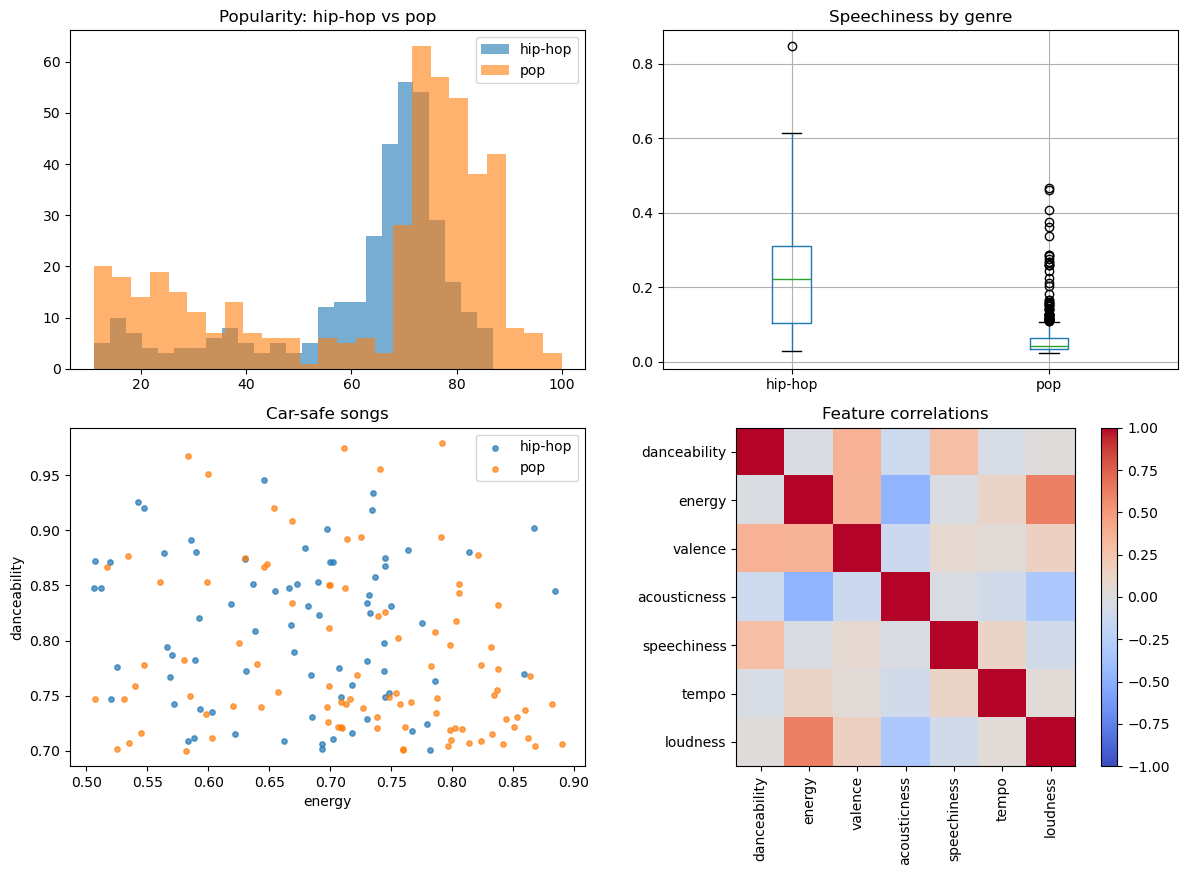

In [78]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 2, figsize=(12, 9))

for g in hp:
    ax[0, 0].hist(df_hp[df_hp["playlist_genre"] == g]["track_popularity"],
                  bins=25, alpha=0.6, label=g)
ax[0, 0].set_title("Popularity: hip-hop vs pop"); ax[0, 0].legend()

df_hp.boxplot(column="speechiness", by="playlist_genre", ax=ax[0, 1])
ax[0, 1].set_title("Speechiness by genre"); ax[0, 1].set_xlabel("")

for g in hp:
    s = safe_hp[safe_hp["playlist_genre"] == g]
    ax[1, 0].scatter(s["energy"], s["danceability"], s=15, alpha=0.7, label=g)
ax[1, 0].set_xlabel("energy"); ax[1, 0].set_ylabel("danceability")
ax[1, 0].set_title("Car-safe songs"); ax[1, 0].legend()

corr = df_hp[features].corr()
im = ax[1, 1].imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax[1, 1].set_xticks(range(len(features))); ax[1, 1].set_xticklabels(features, rotation=90)
ax[1, 1].set_yticks(range(len(features))); ax[1, 1].set_yticklabels(features)
ax[1, 1].set_title("Feature correlations"); fig.colorbar(im, ax=ax[1, 1])

plt.suptitle(""); plt.tight_layout(); plt.show()

In [ ]:
## Findings
# Pop songs in this dataset reach higher popularity scores than hip-hop and also include many low-popularity tracks, while hip-hop is concentrated between roughly 55 and 85.
# Speechiness separates the genres clearly: hip-hop's median is about 0.22 versus about 0.04 for pop.
# Among car-safe songs, hip-hop and pop overlap heavily on energy and danceability, so those features alone cannot distinguish genre.
# Energy and loudness are the most strongly correlated features, and energy is negatively correlated with acousticness, meaning some features carry overlapping information.

In [79]:
from sklearn.neighbors import NearestNeighbors

Zh = Z[df_hp.index]
gh = df_hp["playlist_genre"].to_numpy()
_, idx = NearestNeighbors(n_neighbors=6).fit(Zh).kneighbors(Zh)

model_score = (gh[idx[:, 1:]] == gh[:, None]).mean()
rng = np.random.default_rng(42)
random_score = (gh[rng.integers(0, len(gh), (len(gh), 5))] == gh[:, None]).mean()

print("Genre match, recommender:", round(model_score, 3))
print("Genre match, random:     ", round(random_score, 3))

Genre match, recommender: 0.792
Genre match, random:      0.514
